# Data Profiling — Home Credit Application Data

In [55]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path("data.csv")
OUTPUT_DIR = Path("output") / "profiling"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected the application data at {DATA_PATH.resolve()}.")

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print("Profiling environment ready.")

Profiling environment ready.


## 1. Shape, Schema & Row Identity

In [56]:
df = pd.read_csv(DATA_PATH)

schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_rate": df.isna().mean(),
    "n_unique": df.nunique(dropna=False),
})
schema.index.name = "column"

overview = pd.Series({
    "rows": len(df),
    "columns": df.shape[1],
    "numeric_columns": df.select_dtypes(include=np.number).shape[1],
    "categorical_columns": df.select_dtypes(exclude=np.number).shape[1],
    "memory_mb": df.memory_usage(deep=True).sum() / 1024**2,
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_ids": int(df["SK_ID_CURR"].duplicated().sum()),
    "missing_ids": int(df["SK_ID_CURR"].isna().sum()),
})

display(overview.to_frame("value"))
display(schema.groupby("dtype").size().rename("columns").to_frame())
assert len(df) == 307_511 and df.shape[1] == 122
assert overview["duplicate_rows"] == 0 and overview["duplicate_ids"] == 0

,value
rows,"307,511.0000"
columns,122.0000
numeric_columns,106.0000
categorical_columns,16.0000
memory_mb,536.6916
duplicate_rows,0.0000
duplicate_ids,0.0000
missing_ids,0.0000


,columns
dtype,
float64,65
int64,41
object,16


## 2. Target Balance

,rows,share
TARGET,,
0 — non-default,282686,0.9193
1 — default,24825,0.0807


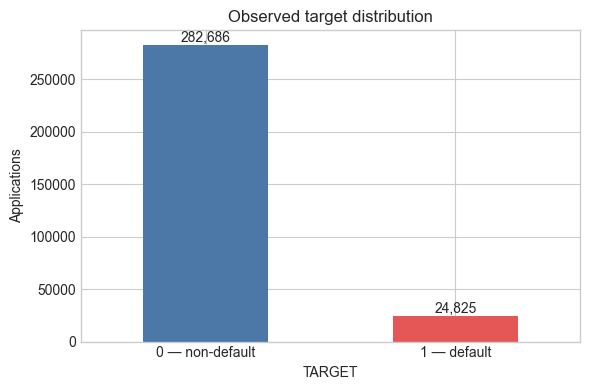

In [57]:
target_counts = df["TARGET"].value_counts(dropna=False).rename("rows").to_frame()
target_counts["share"] = target_counts["rows"] / len(df)
target_counts.index = target_counts.index.map({0: "0 — non-default", 1: "1 — default"})
display(target_counts)

fig, ax = plt.subplots(figsize=(6, 4))
target_counts["rows"].plot.bar(ax=ax, color=["#4C78A8", "#E45756"], rot=0)
ax.set(title="Observed target distribution", ylabel="Applications")
for index, value in enumerate(target_counts["rows"]):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Missingness

67 fields have at least one missing value.


,column,dtype,missing,missing_rate,n_unique
48,COMMONAREA_AVG,float64,214865,0.6987,3182
76,COMMONAREA_MEDI,float64,214865,0.6987,3203
62,COMMONAREA_MODE,float64,214865,0.6987,3129
56,NONLIVINGAPARTMENTS_AVG,float64,213514,0.6943,387
84,NONLIVINGAPARTMENTS_MEDI,float64,213514,0.6943,215
70,NONLIVINGAPARTMENTS_MODE,float64,213514,0.6943,168
86,FONDKAPREMONT_MODE,object,210295,0.6839,5
54,LIVINGAPARTMENTS_AVG,float64,210199,0.6835,1869
82,LIVINGAPARTMENTS_MEDI,float64,210199,0.6835,1098
68,LIVINGAPARTMENTS_MODE,float64,210199,0.6835,737


,n_unique,most_common_share,missing_rate
FLAG_DOCUMENT_11,2,0.9961,0.0000
FLAG_DOCUMENT_9,2,0.9961,0.0000
FLAG_DOCUMENT_13,2,0.9965,0.0000
FLAG_DOCUMENT_14,2,0.9971,0.0000
FLAG_CONT_MOBILE,2,0.9981,0.0000
FLAG_DOCUMENT_15,2,0.9988,0.0000
FLAG_DOCUMENT_19,2,0.9994,0.0000
FLAG_DOCUMENT_20,2,0.9995,0.0000
FLAG_DOCUMENT_21,2,0.9997,0.0000
FLAG_DOCUMENT_17,2,0.9997,0.0000


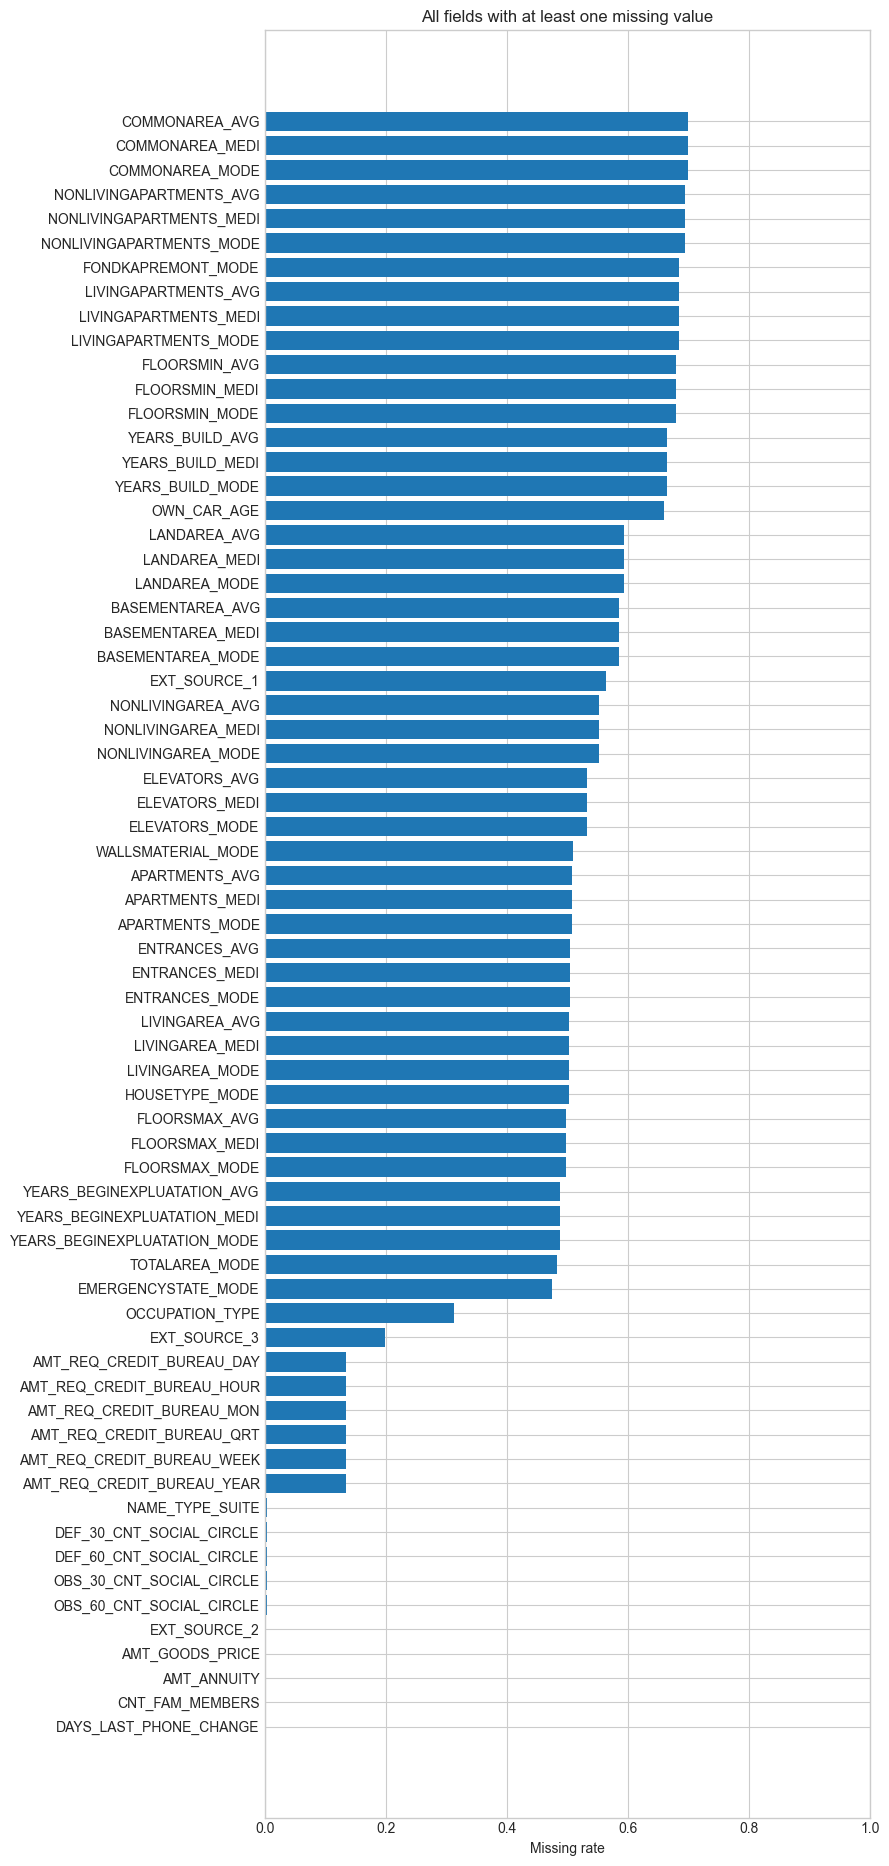

In [58]:
missingness = (
    schema.reset_index()
    .sort_values(["missing_rate", "column"], ascending=[False, True])
    .loc[:, ["column", "dtype", "missing", "missing_rate", "n_unique"]]
)
missing_fields = missingness[missingness["missing"].gt(0)]

mode_share = pd.Series({
    column: df[column].value_counts(dropna=False, normalize=True).iloc[0]
    for column in df.columns
}, name="most_common_share")
low_information = pd.DataFrame({
    "n_unique": schema["n_unique"],
    "most_common_share": mode_share,
    "missing_rate": schema["missing_rate"],
})
low_information = low_information[
    low_information["n_unique"].le(1) | low_information["most_common_share"].ge(0.995)
].sort_values(["n_unique", "most_common_share"])

print(f"{len(missing_fields)} fields have at least one missing value.")
display(missing_fields)
display(low_information)

fig, ax = plt.subplots(figsize=(9, max(6, 0.28 * len(missing_fields))))
all_missing = missing_fields.iloc[::-1]
ax.barh(all_missing["column"], all_missing["missing_rate"])
ax.set(title="All fields with at least one missing value", xlabel="Missing rate", xlim=(0, 1))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "missingness.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Categorical Value

In [59]:
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()
categorical_counts = {
    column: df[column].value_counts(dropna=False) for column in categorical_columns
}
categorical_rows = []
categorical_value_frames = []
for column, counts in categorical_counts.items():
    missing = int(df[column].isna().sum())
    categorical_rows.append({
        "column": column,
        "distinct_categories": counts.size,
        "missing": missing,
        "missing_pct": 100 * missing / len(df),
        "most_common": str(counts.index[0]),
        "most_common_share": counts.iloc[0] / len(df),
        "rarest_observed_count": int(counts.iloc[-1]),
    })
    categorical_value_frames.append(pd.DataFrame({
        "feature": column,
        "category": ["Missing" if pd.isna(value) else str(value) for value in counts.index],
        "count": counts.to_numpy(),
        "share": counts.to_numpy() / len(df),
    }))
categorical_summary = pd.DataFrame(categorical_rows).sort_values(
    "distinct_categories", ascending=False
)
categorical_values = pd.concat(categorical_value_frames, ignore_index=True)
display(categorical_summary)

for column, counts in categorical_counts.items():
    print(f"\n{column} — {counts.size} categories")
    display((counts.head(12) / len(df)).rename("share").to_frame())

,column,distinct_categories,missing,missing_pct,most_common,most_common_share,rarest_observed_count
11,ORGANIZATION_TYPE,58,0,0.0000,Business Entity Type 3,0.2211,24
9,OCCUPATION_TYPE,19,96391,31.3455,nan,0.3135,526
4,NAME_TYPE_SUITE,8,1292,0.4201,Unaccompanied,0.8082,271
5,NAME_INCOME_TYPE,8,0,0.0000,Working,0.5163,5
14,WALLSMATERIAL_MODE,8,156341,50.8408,nan,0.5084,1625
10,WEEKDAY_APPR_PROCESS_START,7,0,0.0000,TUESDAY,0.1753,16181
7,NAME_FAMILY_STATUS,6,0,0.0000,Married,0.6388,2
8,NAME_HOUSING_TYPE,6,0,0.0000,House / apartment,0.8873,1122
6,NAME_EDUCATION_TYPE,5,0,0.0000,Secondary / secondary special,0.7102,164
12,FONDKAPREMONT_MODE,5,210295,68.3862,nan,0.6839,5619



NAME_CONTRACT_TYPE — 2 categories


,share
NAME_CONTRACT_TYPE,
Cash loans,0.9048
Revolving loans,0.0952



CODE_GENDER — 3 categories


,share
CODE_GENDER,
F,0.6583
M,0.3416
XNA,0.0000



FLAG_OWN_CAR — 2 categories


... (23 outputs left out)


WALLSMATERIAL_MODE — 8 categories


,share
WALLSMATERIAL_MODE,
NaN,0.5084
Panel,0.2148
"Stone, brick",0.2108
Block,0.0301
Wooden,0.0174
Mixed,0.0075
Monolithic,0.0058
Others,0.0053



EMERGENCYSTATE_MODE — 3 categories


,share
EMERGENCYSTATE_MODE,
No,0.5184
NaN,0.4740
Yes,0.0076


## 5. Numeric Range & Sentinel Value

,count,mean,std,min,25%,50%,75%,max,missing_rate,p99
column,,,,,,,,,,
TARGET,"307,511.0000",0.0807,0.2724,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000
CNT_CHILDREN,"307,511.0000",0.4171,0.7221,0.0000,0.0000,0.0000,1.0000,19.0000,0.0000,3.0000
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","112,500.0000","147,150.0000","202,500.0000","117,000,000.0000",0.0000,"472,500.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","270,000.0000","513,531.0000","808,650.0000","4,050,000.0000",0.0000,"1,854,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","16,524.0000","24,903.0000","34,596.0000","258,025.5000",0.0000,"70,006.5000"
AMT_GOODS_PRICE,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","238,500.0000","450,000.0000","679,500.0000","4,050,000.0000",0.0009,"1,800,000.0000"
DAYS_BIRTH,"307,511.0000","-16,036.9951","4,363.9886","-25,229.0000","-19,682.0000","-15,750.0000","-12,413.0000","-7,489.0000",0.0000,"-8,263.0000"
DAYS_EMPLOYED,"307,511.0000","63,815.0459","141,275.7665","-17,912.0000","-2,760.0000","-1,213.0000",-289.0000,"365,243.0000",0.0000,"365,243.0000"
EXT_SOURCE_1,"134,133.0000",0.5021,0.2111,0.0146,0.3340,0.5060,0.6751,0.9627,0.5638,0.8894


,check,rows,share
0,DAYS_EMPLOYED sentinel (365243),55374,0.1801
1,DAYS_BIRTH not negative,0,0.0000
2,Age outside 18–100,0,0.0000
3,CODE_GENDER = XNA,4,0.0000
4,NAME_FAMILY_STATUS = Unknown,2,0.0000
5,Nonpositive income,0,0.0000
6,Nonpositive credit,0,0.0000
7,Nonpositive annuity,0,0.0000
8,"EXT_SOURCE outside [0, 1]",0,0.0000
9,More than 10 children,8,0.0000


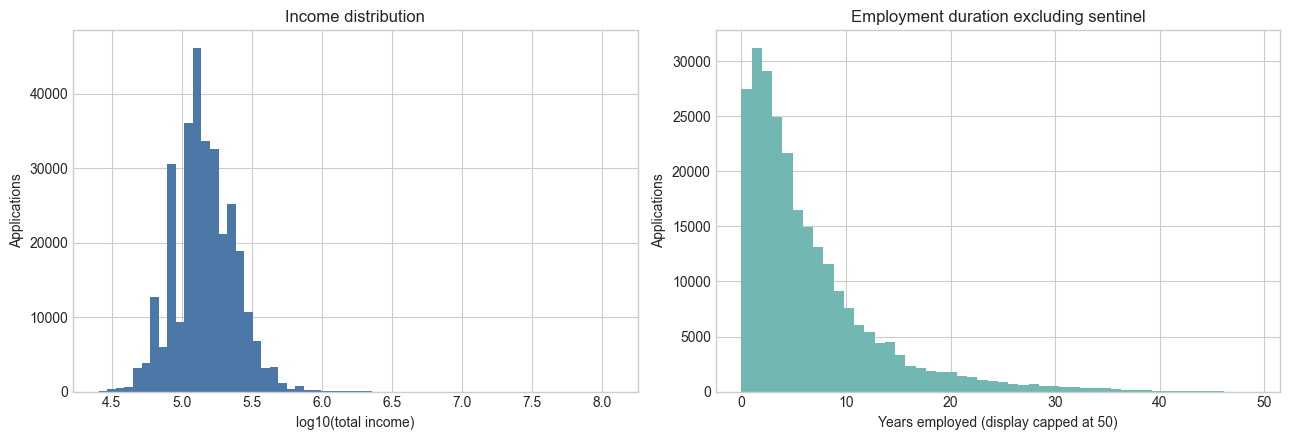

In [60]:
numeric_columns = df.select_dtypes(include=np.number)
numeric_summary = numeric_columns.describe().T
numeric_summary["missing_rate"] = numeric_columns.isna().mean()
numeric_summary["p99"] = numeric_columns.quantile(0.99)
display(numeric_summary.loc[[
    "TARGET", "CNT_CHILDREN", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
    "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3", "CNT_FAM_MEMBERS",
]])

age_years = -df["DAYS_BIRTH"] / 365.25
employment_sentinel = df["DAYS_EMPLOYED"].eq(365243)
external_scores = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
external_out_of_range = external_scores.notna() & ((external_scores < 0) | (external_scores > 1))
anomaly_checks = pd.DataFrame([
    {"check": "DAYS_EMPLOYED sentinel (365243)", "rows": int(employment_sentinel.sum())},
    {"check": "DAYS_BIRTH not negative", "rows": int(df["DAYS_BIRTH"].ge(0).sum())},
    {"check": "Age outside 18–100", "rows": int((~age_years.between(18, 100)).sum())},
    {"check": "CODE_GENDER = XNA", "rows": int(df["CODE_GENDER"].eq("XNA").sum())},
    {"check": "NAME_FAMILY_STATUS = Unknown", "rows": int(df["NAME_FAMILY_STATUS"].eq("Unknown").sum())},
    {"check": "Nonpositive income", "rows": int(df["AMT_INCOME_TOTAL"].le(0).sum())},
    {"check": "Nonpositive credit", "rows": int(df["AMT_CREDIT"].le(0).sum())},
    {"check": "Nonpositive annuity", "rows": int(df["AMT_ANNUITY"].fillna(1).le(0).sum())},
    {"check": "EXT_SOURCE outside [0, 1]", "rows": int(external_out_of_range.any(axis=1).sum())},
    {"check": "More than 10 children", "rows": int(df["CNT_CHILDREN"].gt(10).sum())},
])
anomaly_checks["share"] = anomaly_checks["rows"] / len(df)
display(anomaly_checks)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(np.log10(df["AMT_INCOME_TOTAL"]), bins=60, color="#4C78A8")
axes[0].set(title="Income distribution", xlabel="log10(total income)", ylabel="Applications")
valid_employment_years = -df.loc[~employment_sentinel, "DAYS_EMPLOYED"] / 365.25
axes[1].hist(valid_employment_years.clip(upper=50), bins=50, color="#72B7B2")
axes[1].set(title="Employment duration excluding sentinel", xlabel="Years employed (display capped at 50)", ylabel="Applications")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "income_employment_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Potential Group Used in Fairness Audit


gender


,gender,rows,defaults,default_rate,share_of_data
0,Female,202448,14170,0.0700,0.6583
1,Male,105059,10655,0.1014,0.3416
2,Unknown/XNA,4,0,0.0000,0.0000



age_band


,age_band,rows,defaults,default_rate,share_of_data
0,35–44,84261,7085,0.0841,0.2740
1,25–34,72429,7721,0.1066,0.2355
2,45–54,70190,4946,0.0705,0.2283
3,55–64,60522,3281,0.0542,0.1968
4,<25,12233,1504,0.1229,0.0398
5,65+,7876,288,0.0366,0.0256



income_band


,income_band,rows,defaults,default_rate,share_of_data
0,Q1 low,100578,8443,0.0839,0.3271
1,Q3,82213,6902,0.0840,0.2673
2,Q4 high,71538,4943,0.0691,0.2326
3,Q2,53182,4537,0.0853,0.1729



education


,education,rows,defaults,default_rate,share_of_data
0,Secondary / secondary special,218391,19524,0.0894,0.7102
1,Higher education,74863,4009,0.0536,0.2434
2,Incomplete higher,10277,872,0.0848,0.0334
3,Lower secondary,3816,417,0.1093,0.0124
4,Academic degree,164,3,0.0183,0.0005



family_status


,family_status,rows,defaults,default_rate,share_of_data
0,Married,196432,14850,0.0756,0.6388
1,Single / not married,45444,4457,0.0981,0.1478
2,Civil marriage,29775,2961,0.0994,0.0968
3,Separated,19770,1620,0.0819,0.0643
4,Widow,16088,937,0.0582,0.0523
5,Unknown,2,0,0.0000,0.0000


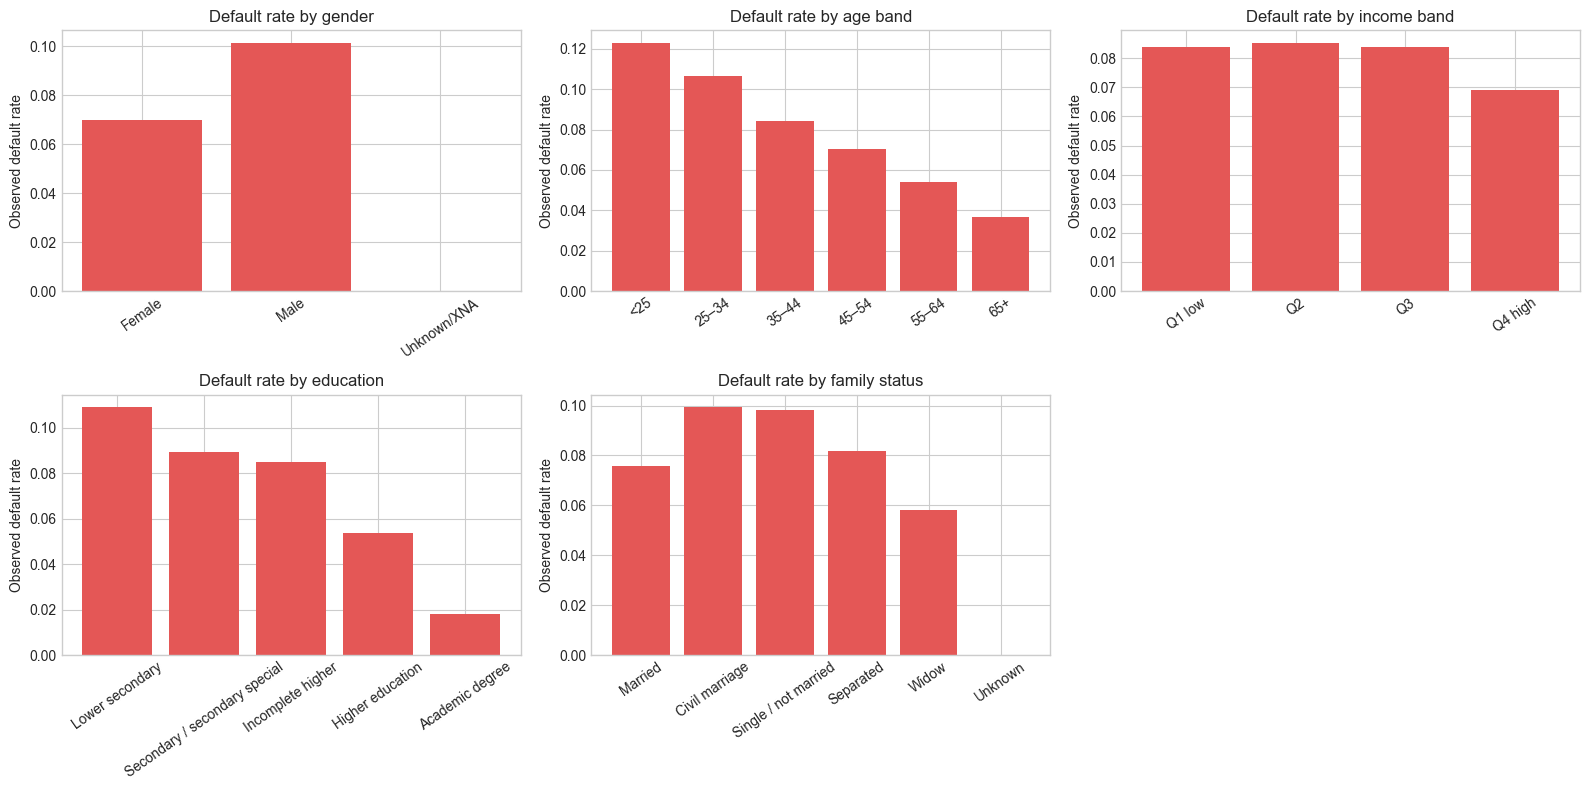

In [61]:
profile = df.copy()
profile["gender"] = profile["CODE_GENDER"].map({"F": "Female", "M": "Male"}).fillna("Unknown/XNA")
profile["age_years"] = age_years
profile["age_band"] = pd.cut(
    profile["age_years"], bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=["<25", "25–34", "35–44", "45–54", "55–64", "65+"], right=False,
).astype("string")
income_quartiles = profile["AMT_INCOME_TOTAL"].quantile([0.25, 0.50, 0.75]).to_numpy()
profile["income_band"] = pd.cut(
    profile["AMT_INCOME_TOTAL"], bins=[-np.inf, *income_quartiles, np.inf],
    labels=["Q1 low", "Q2", "Q3", "Q4 high"], include_lowest=True,
).astype("string")
profile["education"] = profile["NAME_EDUCATION_TYPE"].fillna("Missing")
profile["family_status"] = profile["NAME_FAMILY_STATUS"].fillna("Missing")


def group_profile(frame, column):
    grouped = frame.groupby(column, observed=True, dropna=False)["TARGET"].agg(
        rows="size", defaults="sum", default_rate="mean"
    )
    grouped["share_of_data"] = grouped["rows"] / len(frame)
    return grouped.sort_values("rows", ascending=False).reset_index()


group_tables = {
    column: group_profile(profile, column)
    for column in ["gender", "age_band", "income_band", "education", "family_status"]
}
for column, table in group_tables.items():
    print(f"\n{column}")
    display(table)

plot_specs = [
    ("gender", "Gender", ["Female", "Male", "Unknown/XNA"]),
    ("age_band", "Age band", ["<25", "25–34", "35–44", "45–54", "55–64", "65+"]),
    ("income_band", "Income band", ["Q1 low", "Q2", "Q3", "Q4 high"]),
    ("education", "Education", [
        "Lower secondary", "Secondary / secondary special", "Incomplete higher",
        "Higher education", "Academic degree",
    ]),
    ("family_status", "Family status", [
        "Married", "Civil marriage", "Single / not married", "Separated", "Widow", "Unknown",
    ]),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (column, title, order) in zip(axes.ravel(), plot_specs):
    table = group_tables[column].set_index(column).reindex(order).dropna(subset=["default_rate"])
    ax.bar(table.index.astype(str), table["default_rate"], color="#E45756")
    ax.set(title=f"Default rate by {title.lower()}", ylabel="Observed default rate")
    ax.tick_params(axis="x", rotation=35)
axes.ravel()[-1].axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "group_default_rates.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Missingness & External Credit Score By Gender

field,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,OCCUPATION_TYPE,NAME_TYPE_SUITE,OWN_CAR_AGE,AMT_REQ_CREDIT_BUREAU_YEAR
gender,,,,,,,
Female,0.5473,0.0025,0.1907,0.3614,0.0040,0.7779,0.1293
Male,0.5956,0.0015,0.2128,0.2210,0.0046,0.4325,0.1460
Unknown/XNA,0.5000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000


column      EXT_SOURCE_1               EXT_SOURCE_2                \
                   count median   mean        count median   mean   
gender                                                              
Female             91640 0.5583 0.5462       201946 0.5679 0.5164   
Male               42491 0.3808 0.4071       104901 0.5620 0.5105   
Unknown/XNA            2 0.5290 0.5290            4 0.6589 0.5808   

column      EXT_SOURCE_3                
                   count median   mean  
gender                                  
Female            163835 0.5407 0.5140  
Male               82707 0.5263 0.5045  
Unknown/XNA            4 0.3357 0.3025

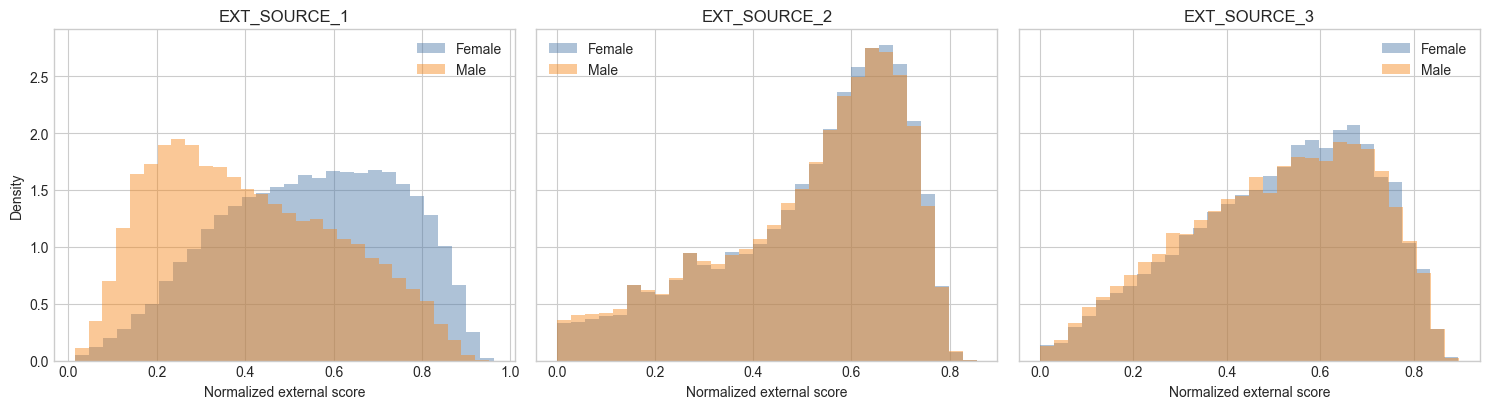

In [62]:
key_fields = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "OCCUPATION_TYPE",
    "NAME_TYPE_SUITE", "OWN_CAR_AGE", "AMT_REQ_CREDIT_BUREAU_YEAR",
]
missing_by_gender = (
    profile.groupby("gender")[key_fields]
    .agg(lambda values: values.isna().mean())
    .rename_axis(index="gender", columns="field")
)
display(missing_by_gender)

score_by_gender = (
    profile.groupby("gender")[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
    .agg(["count", "median", "mean"])
)
display(score_by_gender)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, field in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    for gender, color in [("Female", "#4C78A8"), ("Male", "#F58518")]:
        values = profile.loc[profile["gender"].eq(gender), field].dropna()
        ax.hist(values, bins=30, density=True, alpha=0.45, label=gender, color=color)
    ax.set(title=field, xlabel="Normalized external score")
    ax.legend()
axes[0].set_ylabel("Density")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "external_scores_by_gender.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Saved Profiling Output

Tables and figures are written to `output/profiling/`. Run the preceding sections before this cell.

In [63]:
schema.reset_index().to_csv(OUTPUT_DIR / "schema.csv", index=False)
missingness.to_csv(OUTPUT_DIR / "missingness.csv", index=False)
low_information.reset_index(names="column").to_csv(OUTPUT_DIR / "low_information_fields.csv", index=False)
categorical_summary.to_csv(OUTPUT_DIR / "categorical_summary.csv", index=False)
categorical_values.to_csv(OUTPUT_DIR / "categorical_values.csv", index=False)
numeric_summary.reset_index(names="column").to_csv(OUTPUT_DIR / "numeric_summary.csv", index=False)
anomaly_checks.to_csv(OUTPUT_DIR / "anomaly_checks.csv", index=False)
missing_by_gender.reset_index().to_csv(OUTPUT_DIR / "missingness_by_gender.csv", index=False)
excluded_gender = df["CODE_GENDER"].eq("XNA")
excluded_family = df["NAME_FAMILY_STATUS"].eq("Unknown")
exclusion_summary = pd.DataFrame({
    "rule": [
        "CODE_GENDER = XNA",
        "NAME_FAMILY_STATUS = Unknown",
        "Both rules",
        "Either rule",
        "Retained for modeling",
    ],
    "rows": [
        int(excluded_gender.sum()),
        int(excluded_family.sum()),
        int((excluded_gender & excluded_family).sum()),
        int((excluded_gender | excluded_family).sum()),
        int((~excluded_gender & ~excluded_family).sum()),
    ],
})
exclusion_summary["share"] = exclusion_summary["rows"] / len(df)
exclusion_summary.to_csv(OUTPUT_DIR / "exclusion_summary.csv", index=False)
for column, table in group_tables.items():
    table.to_csv(OUTPUT_DIR / f"group_{column}.csv", index=False)

print("Profiling outputs saved to:", OUTPUT_DIR.resolve())
print(
    f"Rows: {len(df):,} | Default rate: {df['TARGET'].mean():.2%} | "
    f"Fields with missing values: {missing_fields.shape[0]} | "
    f"Employment sentinel rows: {int(employment_sentinel.sum()):,}"
)

Profiling outputs saved to: /Users/beta/Desktop/RDS Audit Project/output/profiling
Rows: 307,511 | Default rate: 8.07% | Fields with missing values: 67 | Employment sentinel rows: 55,374
